# We removed the attribute and it still discriminates

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/proxy-variable-finder/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/proxy-variable-finder/demo.ipynb)

Two groups of applicants have the same distribution of true skill. Past hiring decisions, the training labels, held
one group to a higher bar. A model trained without the group attribute still selects that group far less often,
because other features stand in for it. This notebook finds those features with three screens, then measures what
removing or repairing each one does to fairness and to the two kinds of accuracy. The world is constructed and
declared; every model is a real gradient-boosting fit.

1. The engine
2. The world: same skill, biased history
3. Three proxy screens
4. Seven models
5. The chart
6. Try your own

## 1. The engine

Extracted from `proxy.py` at build time. `generate` draws the world; `screen` runs three proxy screens; `evaluate`
trains a model on half the rows (biased labels), selects the top 30% of the other half, and scores it against both
the biased labels and true skill. `study` repeats everything over three seeds and keeps the min-max spread.

This runs the full study (about a minute), so the numbers match `evidence.txt` exactly.

In [1]:
from __future__ import annotations

from itertools import combinations
from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

SEEDS = [197, 198, 199]


N = 80_000


SELECT = 0.30


FEATURES = ["zip", "exp", "cert", "commute", "shift"]


WORLD: Dict[str, float] = {
    "share_b": 0.30,  # share of applicants in group B
    "zip_gap": 1.4,  # zip index shift for B (no skill content)
    "exp_skill": 0.7,  # how much experience reflects skill
    "exp_gap": 0.5,  # experience lost by B to historical access
    "cert_skill": 0.6,  # how much the certification reflects skill
    "pair_link": 0.85,  # how strongly commute x shift identifies group
    "label_bias": 0.9,  # extra bar past decisions held B to
    "label_noise": 0.6,
}


def generate(n: int = N, seed: int = 197, world: Optional[Dict[str, float]] = None) -> Dict[str, np.ndarray]:
    w = world or WORLD
    rng = np.random.default_rng(seed)
    g = (rng.random(n) < w["share_b"]).astype(int)
    skill = rng.normal(0, 1, n)
    d = {"g": g, "skill": skill}
    d["zip"] = w["zip_gap"] * g + rng.normal(0, 1, n)
    d["exp"] = w["exp_skill"] * skill - w["exp_gap"] * g + rng.normal(0, 0.7, n)
    d["cert"] = w["cert_skill"] * skill + rng.normal(0, 0.8, n)
    c = rng.normal(0, 1, n)
    s = np.abs(rng.normal(0, 1, n))
    linked = rng.random(n) < w["pair_link"]
    # group B: shift has the same sign as commute; group A: opposite sign. Unlinked rows get a random sign.
    sign = np.where(linked, np.where(g == 1, np.sign(c), -np.sign(c)), rng.choice([-1.0, 1.0], n))
    d["commute"], d["shift"] = c, sign * s
    d["y_hist"] = (skill - w["label_bias"] * g + rng.normal(0, w["label_noise"], n) > 0.4).astype(int)
    d["y_true"] = (skill + rng.normal(0, w["label_noise"], n) > 0.4).astype(int)
    return d


def _auc_either(y: np.ndarray, s: np.ndarray) -> float:
    """How well s separates y, direction ignored (a proxy can point either way)."""
    a = roc_auc_score(y, s)
    return float(max(a, 1 - a))


def _fit_auc(d: Dict[str, np.ndarray], cols: List[str], target: str = "g") -> float:
    n = len(d["g"])
    tr, te = slice(0, n // 2), slice(n // 2, n)
    X = np.column_stack([d[c] for c in cols])
    m = HistGradientBoostingClassifier(random_state=0).fit(X[tr], d[target][tr])
    return _auc_either(d[target][te], m.predict_proba(X[te])[:, 1])


def screen(d: Dict[str, np.ndarray]) -> Dict[str, object]:
    """Three proxy screens, from the one most teams run to the one that sees joint proxies."""
    n = len(d["g"])
    te = slice(n // 2, n)
    single = {f: _auc_either(d["g"][te], d[f][te]) for f in FEATURES}
    pairs = {f"{a}+{b}": _fit_auc(d, [a, b]) for a, b in combinations(FEATURES, 2)}
    joint = _fit_auc(d, FEATURES)
    drop_one = {f: joint - _fit_auc(d, [x for x in FEATURES if x != f]) for f in FEATURES}
    return {"single": single, "pairs": pairs, "joint": joint, "drop_one": drop_one}


def _repair(d: Dict[str, np.ndarray], cols: List[str]) -> Dict[str, np.ndarray]:
    """Remove the part of each column that the group predicts in the MEAN (subtract the group mean). This is the
    linear repair most toolkits offer; it cannot touch a proxy that lives in an interaction."""
    out = dict(d)
    for c in cols:
        x = d[c].astype(float).copy()
        for gv in (0, 1):
            m = d["g"] == gv
            x[m] = x[m] - x[m].mean()
        out[c] = x
    return out


MODELS: Dict[str, Dict[str, object]] = {
    "aware (group as a feature)": {"cols": FEATURES, "with_g": True},
    "unaware (group removed)": {"cols": FEATURES},
    "drop zip": {"cols": ["exp", "cert", "commute", "shift"]},
    "drop zip + the commute/shift pair": {"cols": ["exp", "cert"]},
    "linear repair of every feature": {"cols": FEATURES, "repair": FEATURES},
    "drop zip + pair, repair exp": {"cols": ["exp", "cert"], "repair": ["exp"]},
    "cert only": {"cols": ["cert"]},
}


def evaluate(d: Dict[str, np.ndarray], spec: Dict[str, object]) -> Dict[str, float]:
    n = len(d["g"])
    tr, te = slice(0, n // 2), slice(n // 2, n)
    dd = _repair(d, spec.get("repair", [])) if spec.get("repair") else d
    cols = [dd[c] for c in spec["cols"]] + ([dd["g"]] if spec.get("with_g") else [])
    X = np.column_stack(cols)
    m = HistGradientBoostingClassifier(random_state=0).fit(X[tr], d["y_hist"][tr])
    s = m.predict_proba(X[te])[:, 1]
    g, yt, yh = d["g"][te], d["y_true"][te], d["y_hist"][te]
    sel = s >= np.quantile(s, 1 - SELECT)
    sa, sb = sel[g == 0].mean(), sel[g == 1].mean()
    qa, qb = sel[(g == 0) & (yt == 1)].mean(), sel[(g == 1) & (yt == 1)].mean()
    return {"sel_a": float(sa), "sel_b": float(sb), "ratio": float(sb / sa), "auc_hist": float(roc_auc_score(yh, s)),
            "auc_true": float(roc_auc_score(yt, s)), "group_from_score": _auc_either(g, s),
            "qual_sel_a": float(qa), "qual_sel_b": float(qb)}


def study(seeds: Optional[List[int]] = None, n: int = N, world: Optional[Dict[str, float]] = None) -> Dict[str, object]:
    """Every model and the screen on each seed; returns the mean and the min-max spread of every number."""
    seeds = seeds or SEEDS
    per_seed = []
    for sd in seeds:
        d = generate(n, sd, world)
        per_seed.append({"screen": screen(d), "models": {k: evaluate(d, v) for k, v in MODELS.items()}})

    def agg(get) -> Dict[str, float]:
        v = np.array([get(r) for r in per_seed])
        return {"mean": float(v.mean()), "lo": float(v.min()), "hi": float(v.max())}

    models = {k: {m: agg(lambda r, k=k, m=m: r["models"][k][m]) for m in per_seed[0]["models"][k]} for k in MODELS}
    sc0 = per_seed[0]["screen"]
    screen_agg = {
        "single": {f: agg(lambda r, f=f: r["screen"]["single"][f]) for f in sc0["single"]},
        "pairs": {p: agg(lambda r, p=p: r["screen"]["pairs"][p]) for p in sc0["pairs"]},
        "joint": agg(lambda r: r["screen"]["joint"]),
        "drop_one": {f: agg(lambda r, f=f: r["screen"]["drop_one"][f]) for f in sc0["drop_one"]},
    }
    base = generate(n, seeds[0], world)
    truth = {"skill_gap": float(base["skill"][base["g"] == 0].mean() - base["skill"][base["g"] == 1].mean()),
             "hist_rate_a": float(base["y_hist"][base["g"] == 0].mean()),
             "hist_rate_b": float(base["y_hist"][base["g"] == 1].mean()),
             "true_rate_a": float(base["y_true"][base["g"] == 0].mean()),
             "true_rate_b": float(base["y_true"][base["g"] == 1].mean())}
    return {"models": models, "screen": screen_agg, "truth": truth, "seeds": seeds, "n": n}


def flagged(screen_res: Dict[str, object], threshold: float = 0.60) -> Dict[str, List[str]]:
    """What each screen flags at a common bar: AUC for predicting the group above `threshold`."""
    single = [f for f, v in screen_res["single"].items() if v["mean"] > threshold]
    pairs = [p for p, v in screen_res["pairs"].items()
             if v["mean"] > threshold and not any(f in single for f in p.split("+"))]
    return {"single": single, "pairs_hidden_from_single": pairs}


def parse_world(text: str) -> Dict[str, float]:
    """`key=value` overrides of WORLD. Unknown keys and bad numbers raise ValueError."""
    w = dict(WORLD)
    for part in [p.strip() for p in text.split(",") if p.strip()]:
        if "=" not in part:
            raise ValueError(f"expected key=value, got {part!r}")
        k, v = [x.strip() for x in part.split("=", 1)]
        if k not in WORLD:
            raise ValueError(f"unknown parameter {k!r}; known: {', '.join(WORLD)}")
        try:
            w[k] = float(v)
        except ValueError:
            raise ValueError(f"{k} needs a number, got {v!r}") from None
    if not 0 < w["share_b"] < 1 or not 0 <= w["pair_link"] <= 1:
        raise ValueError("share_b must be in (0, 1) and pair_link in [0, 1]")
    return w

In [2]:
r = study()
t, s, fl = r["truth"], r["screen"], flagged(r["screen"])
print(f"study done: {len(r['seeds'])} seeds x n = {r['n']:,}, {len(MODELS)} models each")

study done: 3 seeds x n = 80,000, 7 models each


## 2. The world: same skill, biased history

True skill has the same distribution in both groups, and the share truly qualified is the same. The labels the model
learns from are not: past decisions hired A at nearly three times B's rate.

In [3]:
print(f"skill gap A minus B {t['skill_gap']:+.3f} sd; truly qualified A {t['true_rate_a']:.1%}, B {t['true_rate_b']:.1%}")
print(f"past decisions (the training labels) selected A {t['hist_rate_a']:.1%}, B {t['hist_rate_b']:.1%}")

skill gap A minus B -0.002 sd; truly qualified A 36.4%, B 36.5%
past decisions (the training labels) selected A 36.6%, B 13.0%


## 3. Three proxy screens

The screen most teams run checks one feature at a time. It flags `zip` and `exp` and passes `commute` and `shift`,
each at an AUC of 0.50 for predicting the group. Together, those two predict the group at 0.92: group B's shift sign
follows its commute sign and group A's opposes it, a pattern no single column shows. A drop-one ranking on the joint
model has the opposite blind spot: it ranks `zip`, the strongest single proxy, below the pair, because the pair can
stand in for it.

In [4]:
print("   one feature at a time:  " + "  ".join(f"{f} {v['mean']:.3f}" for f, v in s["single"].items()))
top_pairs = sorted(s["pairs"].items(), key=lambda kv: -kv[1]["mean"])
hidden = [(p, v) for p, v in top_pairs if p in fl["pairs_hidden_from_single"]]
print("   pairs (hidden from the single screen):  " + "  ".join(f"{p} {v['mean']:.3f}" for p, v in hidden))
print(f"   all five together: {s['joint']['mean']:.3f}")
print(f"   flagged at AUC > 0.60 by the single screen: {', '.join(fl['single'])}; missed by it, caught by pairs: {', '.join(fl['pairs_hidden_from_single'])}")
print("   drop-one importance (joint AUC lost when the feature is removed):  "
      + "  ".join(f"{f} {v['mean']:.3f}" for f, v in sorted(s["drop_one"].items(), key=lambda kv: -kv[1]["mean"])))

   one feature at a time:  zip 0.838  exp 0.637  cert 0.502  commute 0.504  shift 0.502
   pairs (hidden from the single screen):  commute+shift 0.923
   all five together: 0.972
   flagged at AUC > 0.60 by the single screen: zip, exp; missed by it, caught by pairs: commute+shift
   drop-one importance (joint AUC lost when the feature is removed):  shift 0.120  commute 0.119  zip 0.030  exp 0.003  cert 0.000


## 4. Seven models

All seven learn from the same biased history. Removing the group only moves the selection ratio from 0.22 to 0.39.
Linear repair (subtract each feature's group mean) reaches 0.58, because the pair's link to the group is not in its
mean. Dropping zip and the pair and repairing experience reaches 1.01 and leaves no trace of the group in the score.
The number the team can measure, AUC against past decisions, falls from 0.844 to 0.805 on the way. AUC against true
skill rises from 0.778 to 0.817. The model was being rewarded for reproducing the old bias.

In [5]:
print(f"{'model':<36} {'B/A ratio':>16} {'AUC vs history':>15} {'AUC vs truth':>13} {'group from score':>17} {'qualified sel A':>16} {'qualified sel B':>16}")
for k in MODELS:
    v = r["models"][k]
    rng = f"{v['ratio']['mean']:.3f} [{v['ratio']['lo']:.2f}-{v['ratio']['hi']:.2f}]"
    print(f"{k:<36} {rng:>16} {v['auc_hist']['mean']:>15.3f} {v['auc_true']['mean']:>13.3f} {v['group_from_score']['mean']:>17.3f} {v['qual_sel_a']['mean']:>16.1%} {v['qual_sel_b']['mean']:>16.1%}")

model                                       B/A ratio  AUC vs history  AUC vs truth  group from score  qualified sel A  qualified sel B
aware (group as a feature)           0.218 [0.22-0.22]           0.844         0.778             0.782            68.9%            20.3%
unaware (group removed)              0.385 [0.37-0.42]           0.836         0.793             0.699            66.0%            31.0%
drop zip                             0.450 [0.37-0.53]           0.834         0.801             0.663            65.0%            34.6%
drop zip + the commute/shift pair    0.639 [0.63-0.65]           0.827         0.812             0.603            62.5%            44.1%
linear repair of every feature       0.582 [0.49-0.68]           0.824         0.805             0.606            62.7%            40.9%
drop zip + pair, repair exp          1.012 [1.00-1.03]           0.805         0.817             0.502            57.5%            57.6%
cert only                            1.002

## 5. The chart

The full audit figure is `proxy_audit.png` (built by `make_chart.py` from `results.json`). Here, the pair drawn: the
two features that each look like noise, coloured by group.

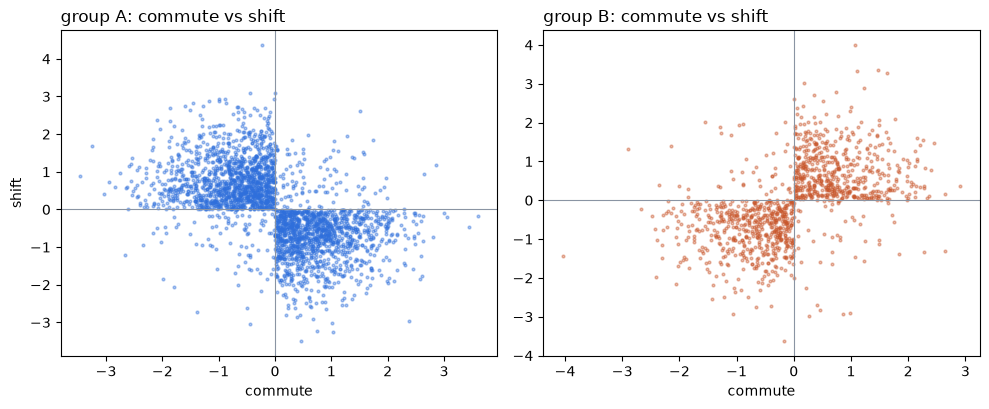

In [6]:
d = generate(4000, SEEDS[0])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (title, gsel) in zip(axes, [("group A", 0), ("group B", 1)]):
    m = d["g"] == gsel
    ax.scatter(d["commute"][m], d["shift"][m], s=4, alpha=0.4, color="#2f6fdb" if gsel == 0 else "#c8562b")
    ax.axhline(0, color="#8a94a3", lw=0.8)
    ax.axvline(0, color="#8a94a3", lw=0.8)
    ax.set_title(f"{title}: commute vs shift", loc="left")
    ax.set_xlabel("commute")
axes[0].set_ylabel("shift")
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- Same skill, biased labels: a model with the group removed still selects B at 0.39 of A's rate.
- A one-feature-at-a-time screen passes two features that together predict the group at 0.92.
- A drop-one ranking hides the strongest single proxy behind a redundant one.
- Linear repair cannot reach a proxy that lives in an interaction.
- Dropping the proxies and repairing the mixed feature reaches parity, and AUC against true skill rises while AUC
  against the biased history falls. Judge a fairness fix against the outcome you want, not against the old decisions.

## 6. Try your own

In [7]:
# A world where the pair is weaker and past decisions were less biased:
# w = parse_world("pair_link=0.4, label_bias=0.4")
# d = generate(30_000, 1, w); print(screen(d)["pairs"]["commute+shift"])
# for k, v in MODELS.items(): print(k, round(evaluate(d, v)["ratio"], 3))

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version takes your own
world: `pip install -r requirements.txt && streamlit run app.py`.

Sibling build: [`disparate-impact`](../disparate-impact) measures the gap between groups and why fairness
definitions conflict; this build finds where the gap enters when the attribute is not even an input.